# Exploratory Data Analysis — Telco Customer Churn

**Goal:** understand the data well enough to make sound preprocessing and modeling decisions.

This notebook is intentionally compact. EDA is for answering questions such as:

- What is the target distribution?
- Are there duplicates or missing values?
- Which variables are numeric/categorical?
- Are there suspicious values?
- Which variables appear related to churn?

We **do not train models or make preprocessing decisions from the test set** here.

## 1. Imports and configuration

In [74]:
# ------------------------- imports -------------------------
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import os

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)

In [75]:
# ------------------------- Paths -------------------------
DATA = '../Data/WA_Fn-UseC_-Telco-Customer-Churn.csv'
RESULTS_DIR = '../Results/'

for d in ([RESULTS_DIR]):
    os.makedirs(d, exist_ok=True)
print("All project directories confirmed and ready.")

All project directories confirmed and ready.


In [76]:
# ------------------------- Var -------------------------
TARGET = "Churn"
RANDOM_STATE = 42

## 2. Load Data as DataFrame

In [77]:
# loading dataset, display 10 samples of it
df = pd.read_csv(DATA).drop(columns=['customerID'])
df.sample(5, random_state=RANDOM_STATE)

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
185,Female,0,Yes,No,1,No,No phone service,DSL,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,24.80,24.8,Yes
2715,Male,0,No,No,41,Yes,Yes,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Month-to-month,Yes,Bank transfer (automatic),25.25,996.45,No
3825,Female,0,Yes,Yes,52,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,19.35,1031.7,No
1807,Female,0,No,No,1,Yes,No,Fiber optic,No,No,Yes,No,No,No,Month-to-month,No,Electronic check,76.35,76.35,Yes
132,Male,0,No,No,67,Yes,No,DSL,No,No,No,Yes,No,No,Two year,No,Bank transfer (automatic),50.55,3260.1,No


## 3. Dataset structure

In [78]:
numeric_cols = df.select_dtypes(include=np.number).columns
categorical_cols = df.select_dtypes(include="str").columns

print(f'Dataset Shape -> Customers: {df.shape[0]}, Features (without Target): {df.shape[1]}')
print('Dataset Dims: ', df.ndim)

print("\nNumerical columns:")
print(numeric_cols.tolist())

print("\nCategorical columns (with Traget):")
print(categorical_cols.tolist())

print()
df.info()

Dataset Shape -> Customers: 7043, Features (without Target): 20
Dataset Dims:  2

Numerical columns:
['SeniorCitizen', 'tenure', 'MonthlyCharges']

Categorical columns (with Traget):
['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'TotalCharges', 'Churn']

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 20 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   gender            7043 non-null   str    
 1   SeniorCitizen     7043 non-null   int64  
 2   Partner           7043 non-null   str    
 3   Dependents        7043 non-null   str    
 4   tenure            7043 non-null   int64  
 5   PhoneService      7043 non-null   str    
 6   MultipleLines     7043 non-null   str    
 7   InternetService   7043 non-

`customerID` identifies a customer but should not be used as a predictive feature. It is removed from the modeling data later.

`SeniorCitizen` is technically numeric in the original file (`0/1`), but it represents a category, so the preprocessing notebook treats it as categorical.

In [79]:
# Small Correction
df['SeniorCitizen'] = df['SeniorCitizen'].astype(str)
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')

numeric_cols = df.select_dtypes(include=np.number).columns
print("Numerical columns:")
print(numeric_cols.tolist())

Numerical columns:
['tenure', 'MonthlyCharges', 'TotalCharges']


In [80]:
categorical_cols = df.select_dtypes(include="str").columns

print('Unique Values for Categorical Features:')
for col in categorical_cols:
    print(f"\n----- {col} -----")
    print(df[col].nunique(), "unique values")
    print(df[col].value_counts().head(20)) # dropna=False

Unique Values for Categorical Features:

----- gender -----
2 unique values
gender
Male      3555
Female    3488
Name: count, dtype: int64

----- SeniorCitizen -----
2 unique values
SeniorCitizen
0    5901
1    1142
Name: count, dtype: int64

----- Partner -----
2 unique values
Partner
No     3641
Yes    3402
Name: count, dtype: int64

----- Dependents -----
2 unique values
Dependents
No     4933
Yes    2110
Name: count, dtype: int64

----- PhoneService -----
2 unique values
PhoneService
Yes    6361
No      682
Name: count, dtype: int64

----- MultipleLines -----
3 unique values
MultipleLines
No                  3390
Yes                 2971
No phone service     682
Name: count, dtype: int64

----- InternetService -----
3 unique values
InternetService
Fiber optic    3096
DSL            2421
No             1526
Name: count, dtype: int64

----- OnlineSecurity -----
3 unique values
OnlineSecurity
No                     3498
Yes                    2019
No internet service    1526
Name: cou

In [81]:
# print('Unique Values for Numaric Features:')
# for col in numeric_cols:
#     print(f"\n----- {col} -----"a)
#     print(df[col].nunique(), "unique values")
#     print(df[col].value_counts().head(20)) # dropna=False

## 4. Dataset Stats for Numaric Features

In [82]:
df[numeric_cols].describe()

,tenure,MonthlyCharges,TotalCharges
count,7043.000000,7043.000000,7032.000000
mean,32.371149,64.761692,2283.300441
std,24.559481,30.090047,2266.771362
min,0.000000,18.250000,18.800000
25%,9.000000,35.500000,401.450000
50%,29.000000,70.350000,1397.475000
75%,55.000000,89.850000,3794.737500
max,72.000000,118.750000,8684.800000


## 5. Explore Duplicates

In [83]:
print("Number of Duplicate Rows:", df.duplicated().sum())

# Droping Duplicates to not skew the data
df.drop_duplicates(inplace=True)

Number of Duplicate Rows: 22


## 6. Missing Values

In [ ]:
missing = (
    df.isna().sum()
    .rename("missing_count")
    .to_frame()
    .assign(missing_percent=lambda x: 100 * x["missing_count"] / len(df))
    .sort_values("missing_count", ascending=False)
)
display(missing[missing["missing_count"] > 0])

,missing_count,missing_percent
TotalCharges,11,0.156183


### Why `TotalCharges` is missing

In this dataset, the missing `TotalCharges` rows correspond to customers with no accumulated tenure/charges yet. The preprocessing notebook therefore uses `0` for these rows.

In [85]:
same_value_cols = rows_with_nan.columns[rows_with_nan.nunique() == 1].tolist()
print('Columns with the same Value for the missing data rows:')
rows_with_nan[same_value_cols]

Columns with the same Value for the missing data rows:


,SeniorCitizen,Dependents,tenure,Churn
488,0,Yes,0,No
753,0,Yes,0,No
936,0,Yes,0,No
1082,0,Yes,0,No
1340,0,Yes,0,No
3331,0,Yes,0,No
3826,0,Yes,0,No
4380,0,Yes,0,No
5218,0,Yes,0,No
6670,0,Yes,0,No


In [86]:
compare_df = pd.DataFrame()
compare_df['TotalCharges'] = df['TotalCharges'].copy()
compare_df['ExpectedTotalCharges'] = df['MonthlyCharges'] * df['tenure']
compare_df['OffsetbetweenCharges'] = np.abs(df['TotalCharges'] - compare_df['ExpectedTotalCharges'])
print(f'The mean of the Offset between TotalCharges & ExpectedTotalCharges: ',np.mean(compare_df['OffsetbetweenCharges']))

compare_df[['TotalCharges', 'ExpectedTotalCharges', 'OffsetbetweenCharges']]

The mean of the Offset between TotalCharges & ExpectedTotalCharges:  45.23066333808845


,TotalCharges,ExpectedTotalCharges,OffsetbetweenCharges
0,29.85,29.85,0.00
1,1889.50,1936.30,46.80
2,108.15,107.70,0.45
3,1840.75,1903.50,62.75
4,151.65,141.40,10.25
...,...,...,...
7038,1990.50,2035.20,44.70
7039,7362.90,7430.40,67.50
7040,346.45,325.60,20.85
7041,306.60,297.60,9.00


## 7. Univariate analysis (Distrbution & Skew)

In [87]:
def get_dest(name):
    skewness = df[name].skew()
    print(f'Skew for {name} feature: {skewness*100}%')

    plt.figure(figsize=(8, 5))
    sns.histplot(data=df, x=name, bins=30, kde=True)
    plt.title(f"{name} Distribution")
    plt.show()

    plt.figure(figsize=(8, 5))
    sns.boxplot(data=df, x=name)
    plt.title(f"{name} Boxplot")
    plt.show()

Skew for tenure feature: 23.554168006988707%


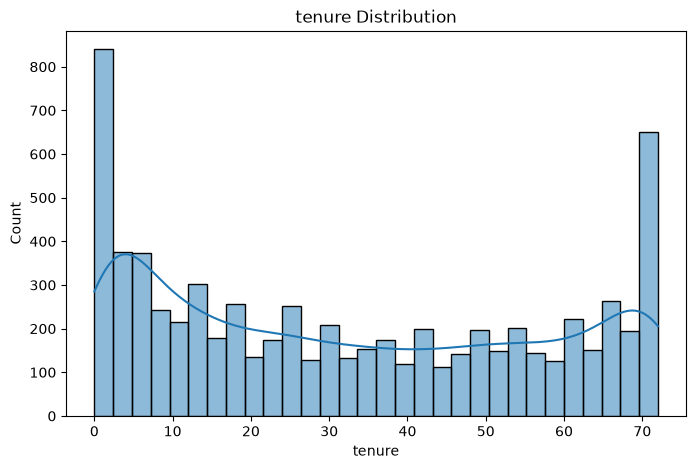

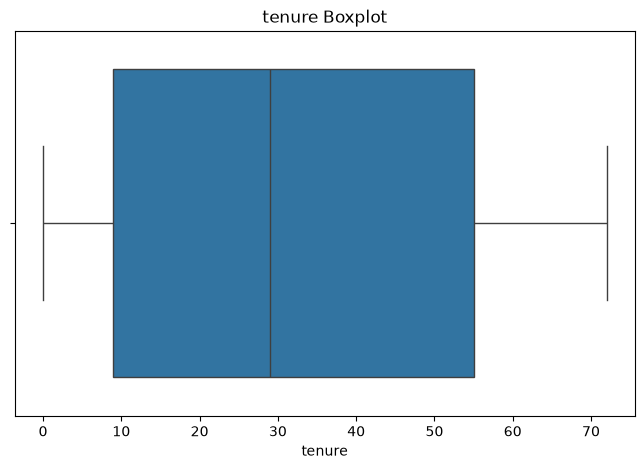

In [88]:
# Tenure
get_dest('tenure')

Skew for MonthlyCharges feature: -22.409728909692607%


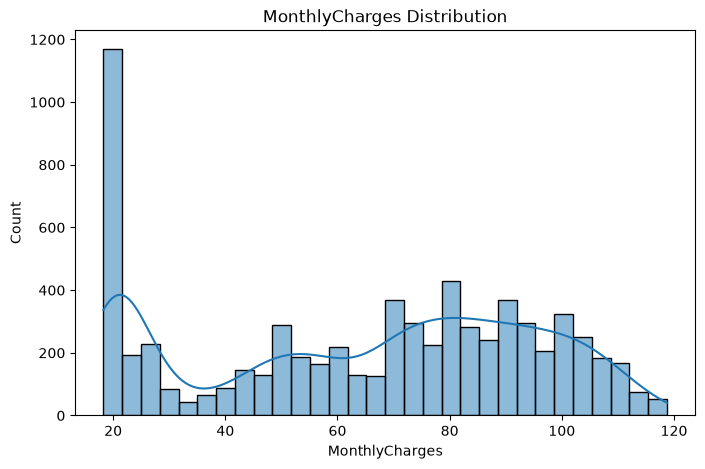

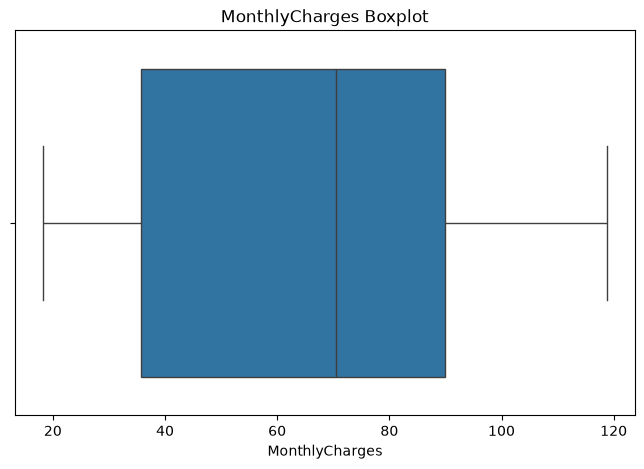

In [89]:
# MonthlyCharges
get_dest('MonthlyCharges')

Skew for TotalCharges feature: 95.83220586626408%


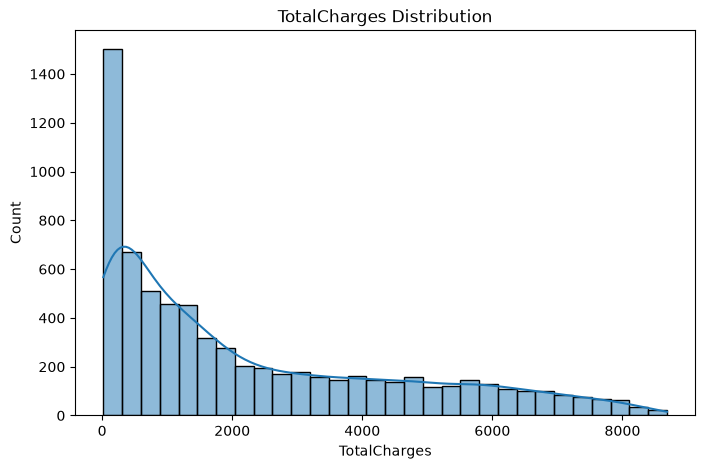

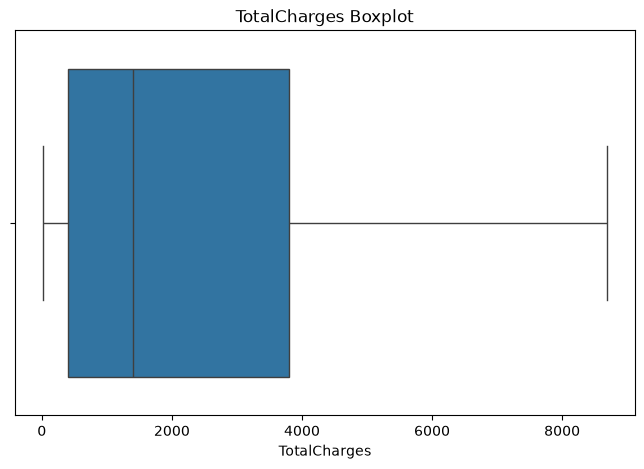

In [90]:
# TotalCharges
get_dest('TotalCharges')

## 8. Outliers
A value being far from the median is not necessarily an error. For churn data, a high `MonthlyCharges` or `TotalCharges` can be a real customer profile.

Tree-based models are also relatively insensitive to monotonic scaling and do not require outlier removal. We therefore **inspect** unusual values but do not delete them merely because they fall outside an IQR rule.

In [91]:
for i in numeric_cols:
    print('\n##',i)
    Q1 = df[i].quantile(0.25)
    Q3 = df[i].quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    print("Lower:", lower_bound)
    print("Upper:", upper_bound)

    outliers = df[(df[i] < lower_bound) |(df[i] > upper_bound)]
    if len(outliers): print(outliers)

    print("Number of Outliers:", len(outliers))


## tenure
Lower: -60.0
Upper: 124.0
Number of Outliers: 0

## MonthlyCharges
Lower: -45.47500000000001
Upper: 171.125
Number of Outliers: 0

## TotalCharges
Lower: -4690.975
Upper: 8907.125
Number of Outliers: 0


## 9. Suspicious Values

To Find values that makes no sence in Numaric data, Like: Negative Numarical Values in tenure.

In [92]:
for i in numeric_cols:
    print("\n##",i)
    sus_valeus = df[df[i] < 0]
    if len(sus_valeus): 
        print(outliers)

    else:
        print('No suspicous values')


## tenure
No suspicous values

## MonthlyCharges
No suspicous values

## TotalCharges
No suspicous values


## 10. Target Variable

In [ ]:
tagret_values = df[TARGET].value_counts()
display(tagret_values.to_frame("count"))

ratio = tagret_values.iloc[0] / tagret_values.iloc[1]
print(f'Ratio between `{tagret_values.index[1]}` & `{tagret_values.index[0]}` = 1 : {ratio:.2f}')

target_rate = tagret_values['Yes'] / tagret_values.sum()
print(f"Churn rate: {target_rate:.2%}")

,count
Churn,
No,5174
Yes,1869


Ratio between `Yes` & `No` = 1 : 2.78
Churn rate: 26.54%


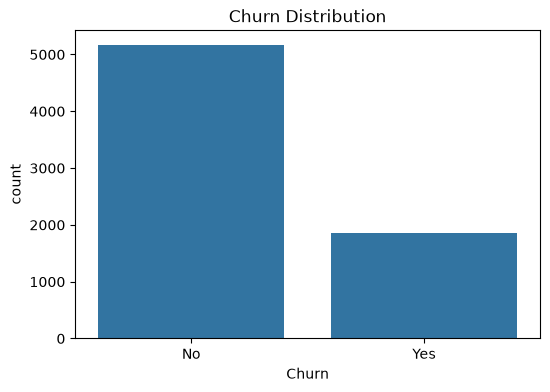

In [94]:
plt.figure(figsize=(6, 4))
sns.countplot(data=df, x=TARGET)
plt.title(f"{TARGET} Distribution")
plt.show()

## 6. Churn rate by important categorical variables


### Contract


,churn_percent,customers
Contract,,
Month-to-month,42.642097,3853
One year,11.269518,1473
Two year,2.831858,1695


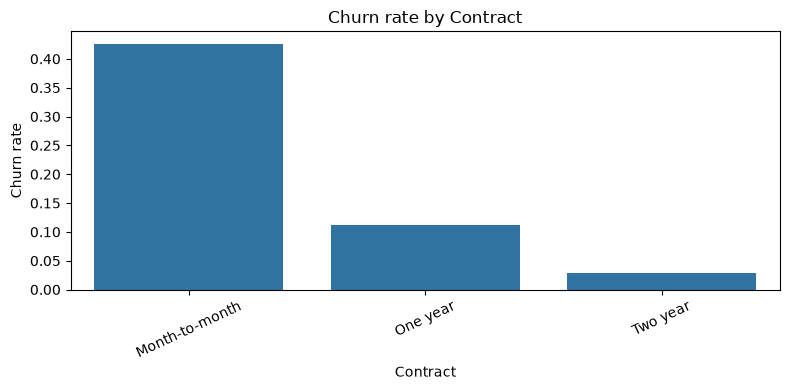


### InternetService


,churn_percent,customers
InternetService,,
Fiber optic,41.779935,3090
DSL,18.892104,2419
No,7.208995,1512


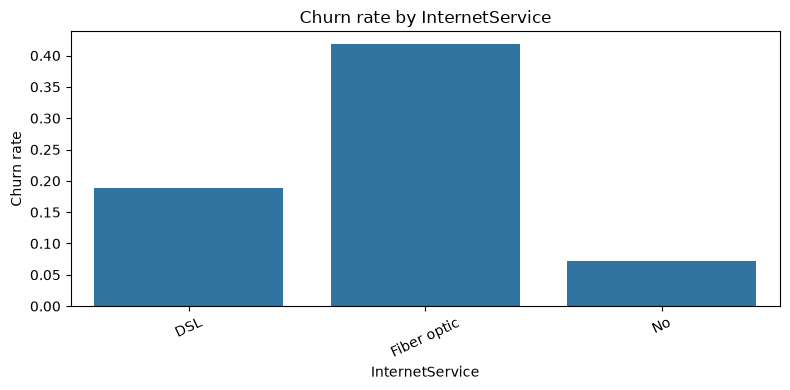


### PaymentMethod


,churn_percent,customers
PaymentMethod,,
Electronic check,45.146248,2359
Mailed check,18.922306,1596
Bank transfer (automatic),16.709845,1544
Credit card (automatic),15.243101,1522


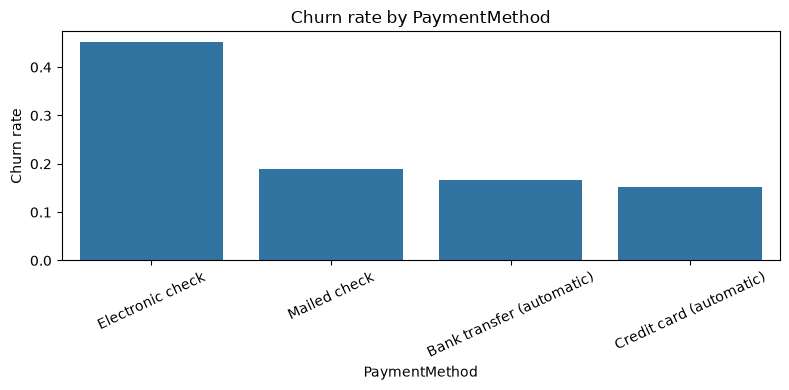


### OnlineSecurity


,churn_percent,customers
OnlineSecurity,,
No,41.633238,3490
Yes,14.611194,2019
No internet service,7.208995,1512


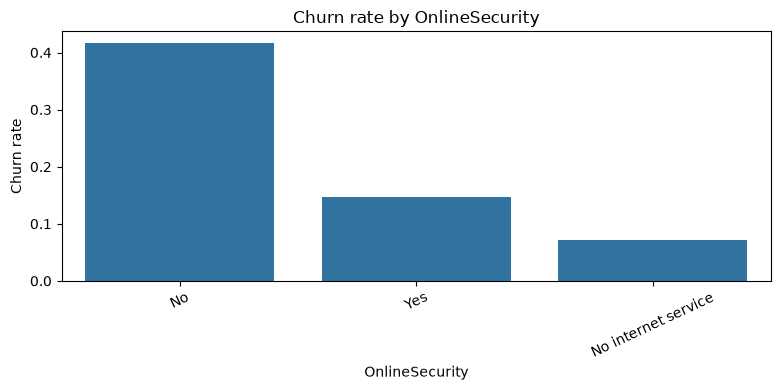


### TechSupport


,churn_percent,customers
TechSupport,,
No,41.500722,3465
Yes,15.166341,2044
No internet service,7.208995,1512


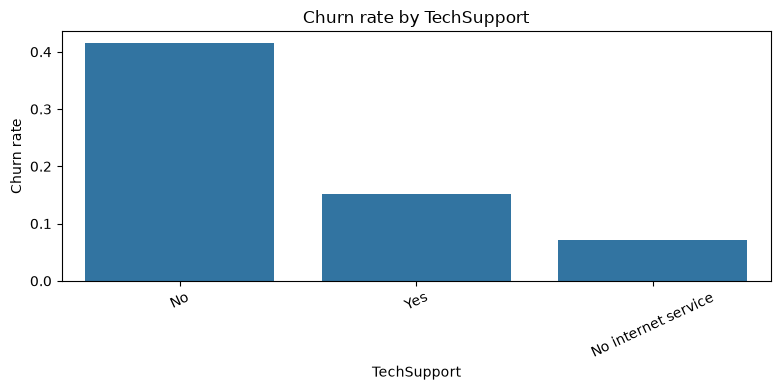


### PaperlessBilling


,churn_percent,customers
PaperlessBilling,,
Yes,33.429464,4161
No,16.293706,2860


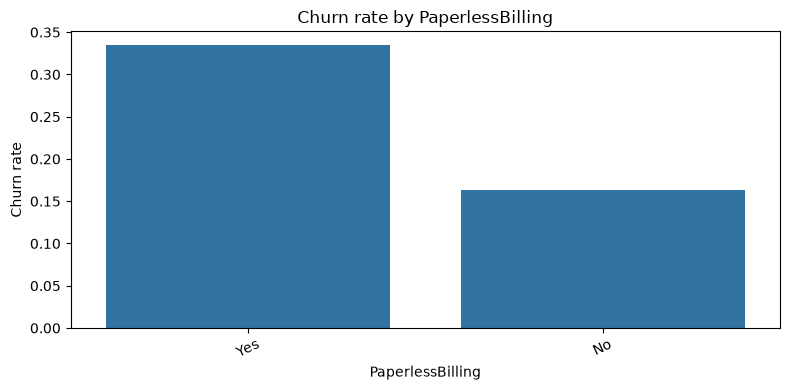

In [95]:
key_cats = [
    "Contract", "InternetService", "PaymentMethod",
    "OnlineSecurity", "TechSupport", "PaperlessBilling"
]

for col in key_cats:
    summary = (
        df.assign(churn=(df[TARGET] == "Yes").astype(int))
          .groupby(col, dropna=False)["churn"]
          .agg(["mean", "count"])
          .sort_values("mean", ascending=False)
    )
    summary["mean"] *= 100

    print(f"\n### {col}")
    display(summary.rename(columns={"mean": "churn_percent", "count": "customers"}))

    fig, ax = plt.subplots(figsize=(8, 4))
    sns.barplot(data=df.assign(churn=(df[TARGET] == "Yes").astype(int)),
                x=col, y="churn", estimator=np.mean, errorbar=None, ax=ax)
    ax.set_title(f"Churn rate by {col}")
    ax.set_ylabel("Churn rate")
    ax.tick_params(axis="x", rotation=25)
    plt.tight_layout()
    plt.show()

## 7. Numeric variables vs churn

These plots are descriptive, not proof of causation. They help us understand whether nonlinear models are likely to be useful.

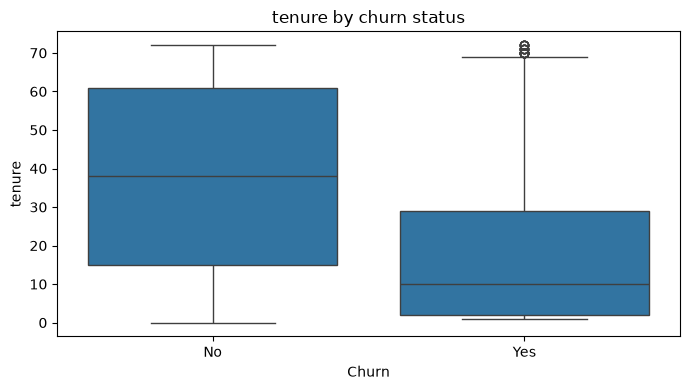

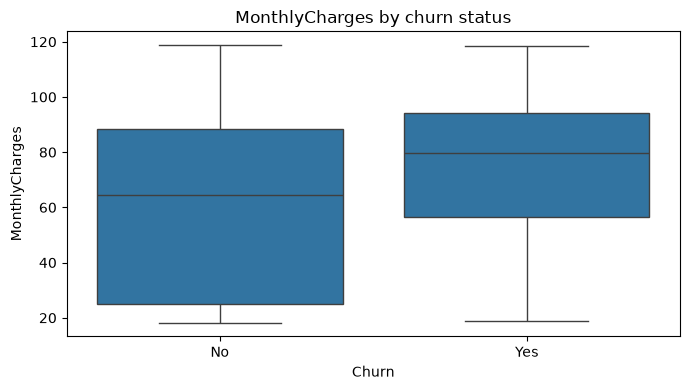

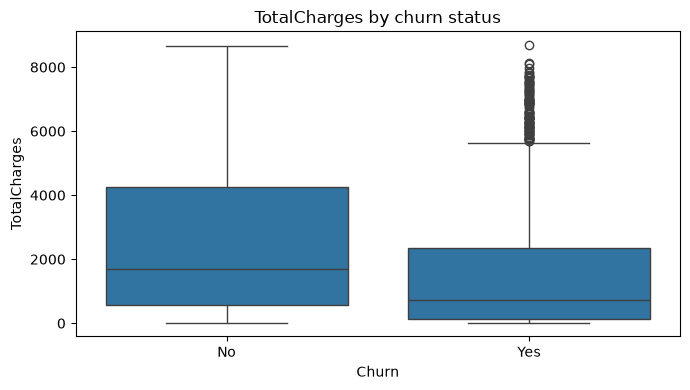

In [96]:
plot_df = df.copy()
plot_df[TARGET] = df[TARGET].values

for col in ["tenure", "MonthlyCharges", "TotalCharges"]:
    fig, ax = plt.subplots(figsize=(7, 4))
    sns.boxplot(data=plot_df, x=TARGET, y=col, ax=ax)
    ax.set_title(f"{col} by churn status")
    plt.tight_layout()
    plt.show()